# The 15 Marron-Wand Gaussian-mixture models

This notebook implements the 15 benchmark normal-mixture densities from Table 1 of Marron and Wand (1992), *Exact Mean Integrated Squared Error*. Each model has its own code cell and produces one two-panel figure: the exact Gaussian-kernel MISE curve on the left and the target density on the right.

The calculations reuse the shared `kde_tools` implementation. Change `SAMPLE_SIZE` in the setup cell to recompute all exact MISE curves for another sample size. Every displayed figure is also exported automatically as a PDF under `outputs/pdfs/marron_wand_15_gmm_mise_density/`.


In [1]:
from __future__ import annotations

import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np

from kde_tools import (
    bandwidth_grid_linear_in_psi_beta,
    exact_mixture_mise_values,
    mixture_density,
)
from kde_tools.pdf_export import enable_automatic_pdf_saving

pdf_output_directory = enable_automatic_pdf_saving(
    "marron_wand_15_gmm_mise_density"
)

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=5, suppress=True)

SAMPLE_SIZE = 100
H_GRID = bandwidth_grid_linear_in_psi_beta(
    h_min=0.005,
    h_max=2.0,
    beta=2.0,
    grid_size=801,
)
DENSITY_POINTS = 4_001
MODEL_RESULTS = {}


def plot_mise_and_density(
    model_number: int,
    model_name: str,
    weights: np.ndarray,
    means: np.ndarray,
    sigmas: np.ndarray,
) -> dict[str, object]:
    """Plot exact MISE and the true density for one normal mixture."""
    weights = np.asarray(weights, dtype=float)
    means = np.asarray(means, dtype=float)
    sigmas = np.asarray(sigmas, dtype=float)

    if not (weights.shape == means.shape == sigmas.shape):
        raise ValueError("weights, means, and sigmas must have the same shape.")
    if np.any(weights < 0.0) or not np.isclose(weights.sum(), 1.0):
        raise ValueError("Mixture weights must be nonnegative and sum to one.")
    if np.any(sigmas <= 0.0):
        raise ValueError("All component standard deviations must be positive.")

    x_min = float(np.min(means - 4.0 * sigmas))
    x_max = float(np.max(means + 4.0 * sigmas))
    x_grid = np.linspace(x_min, x_max, DENSITY_POINTS)

    mise = exact_mixture_mise_values(
        n=SAMPLE_SIZE,
        h_grid=H_GRID,
        weights=weights,
        means=means,
        sigmas=sigmas,
    )
    target_density = mixture_density(
        x=x_grid,
        weights=weights,
        means=means,
        sigmas=sigmas,
    )
    optimal_index = int(np.argmin(mise))
    optimal_h = float(H_GRID[optimal_index])

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    mise_axis, density_axis = axes

    mise_axis.plot(H_GRID, mise, color="tab:blue", linewidth=2.2)
    mise_axis.axvline(
        optimal_h,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=rf"minimum at $h={optimal_h:.4g}$",
    )
    mise_axis.scatter(
        [optimal_h],
        [mise[optimal_index]],
        color="tab:red",
        s=32,
        zorder=3,
    )
    mise_axis.set_xscale("log")
    mise_axis.set_xlabel("bandwidth h (log scale)")
    mise_axis.set_ylabel("MISE(h)")
    mise_axis.set_title(f"Exact Gaussian-kernel MISE (n={SAMPLE_SIZE})")
    mise_axis.legend(loc="best")

    density_axis.plot(x_grid, target_density, color="black", linewidth=2.2)
    density_axis.fill_between(
        x_grid, target_density, color="tab:blue", alpha=0.14
    )
    density_axis.set_xlabel("x")
    density_axis.set_ylabel("density")
    density_axis.set_title("Target Gaussian-mixture density")

    fig.suptitle(f"#{model_number} {model_name}", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.94))
    plt.show()
    plt.close(fig)

    print(
        f"#{model_number} {model_name}: "
        f"{len(weights)} component(s), exact MISE minimum h={optimal_h:.6g}"
    )
    return {
        "name": model_name,
        "weights": weights,
        "means": means,
        "sigmas": sigmas,
        "h_grid": H_GRID,
        "mise": mise,
        "optimal_h": optimal_h,
        "x_grid": x_grid,
        "density": target_density,
    }


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/001_1_gaussian.pdf


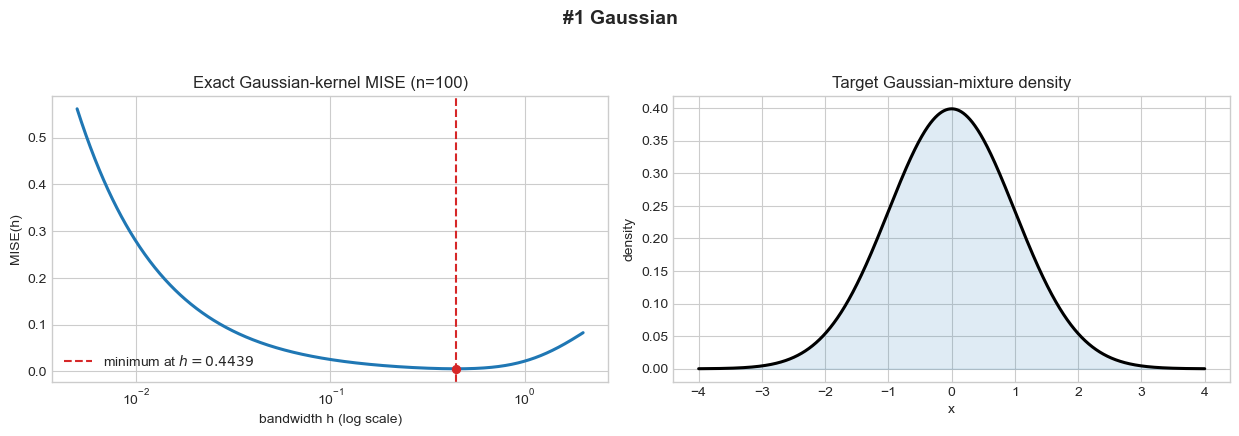

#1 Gaussian: 1 component(s), exact MISE minimum h=0.443877


In [2]:
# 1. Gaussian
weights = np.array([1.0])
means = np.array([0.0])
sigmas = np.array([1.0])

MODEL_RESULTS[1] = plot_mise_and_density(
    1, "Gaussian", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/002_2_skewed_unimodal.pdf


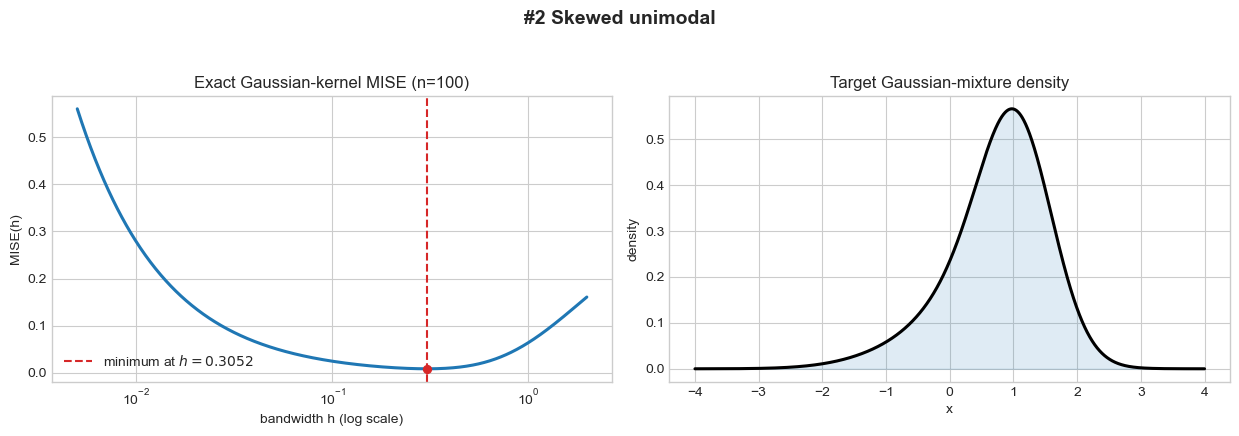

#2 Skewed unimodal: 3 component(s), exact MISE minimum h=0.305235


In [3]:
# 2. Skewed unimodal
weights = np.array([1.0 / 5.0, 1.0 / 5.0, 3.0 / 5.0])
means = np.array([0.0, 1.0 / 2.0, 13.0 / 12.0])
sigmas = np.array([1.0, 2.0 / 3.0, 5.0 / 9.0])

MODEL_RESULTS[2] = plot_mise_and_density(
    2, "Skewed unimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/003_3_strongly_skewed.pdf


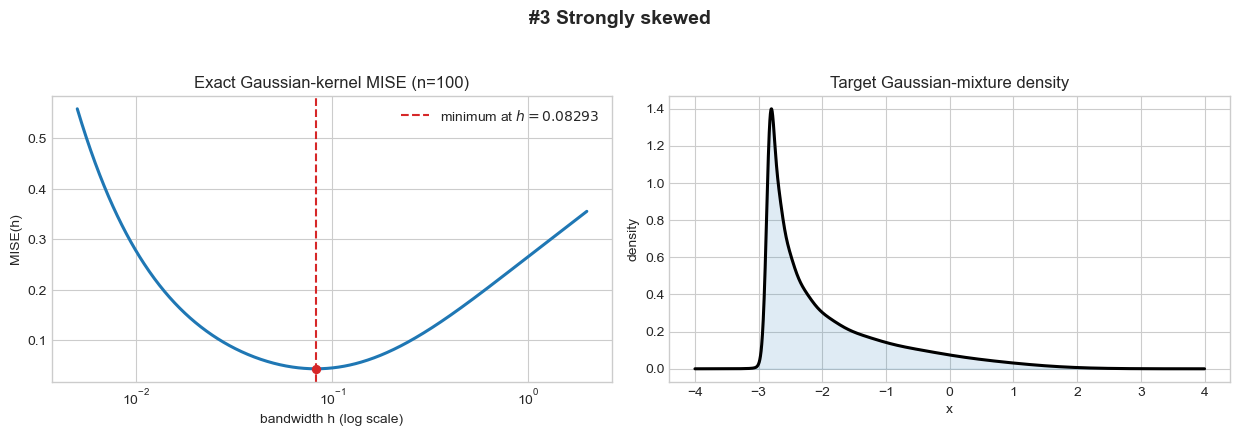

#3 Strongly skewed: 8 component(s), exact MISE minimum h=0.082925


In [4]:
# 3. Strongly skewed
component_index = np.arange(8)
component_scale = (2.0 / 3.0) ** component_index
weights = np.full(8, 1.0 / 8.0)
means = 3.0 * (component_scale - 1.0)
sigmas = component_scale

MODEL_RESULTS[3] = plot_mise_and_density(
    3, "Strongly skewed", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/004_4_kurtotic_unimodal.pdf


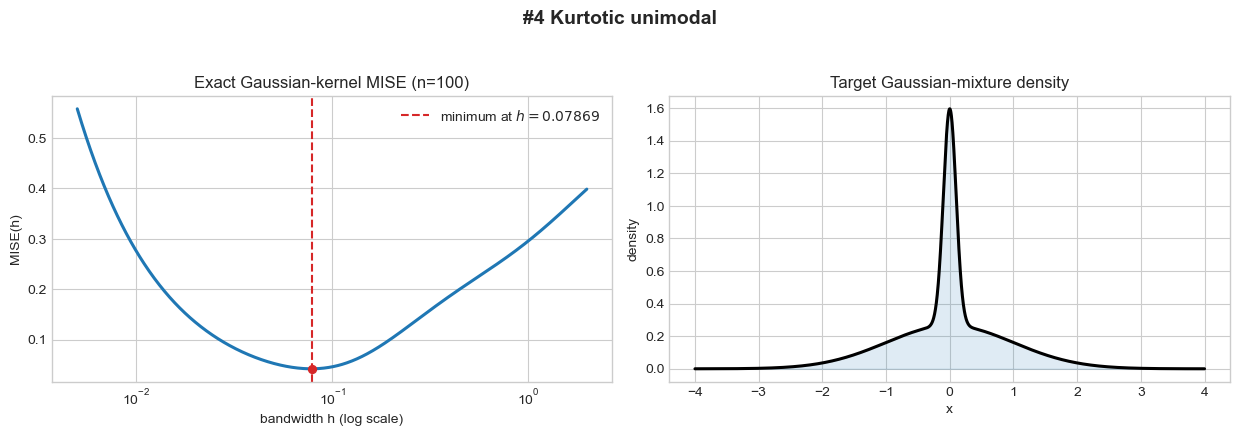

#4 Kurtotic unimodal: 2 component(s), exact MISE minimum h=0.0786896


In [5]:
# 4. Kurtotic unimodal
weights = np.array([2.0 / 3.0, 1.0 / 3.0])
means = np.array([0.0, 0.0])
sigmas = np.array([1.0, 1.0 / 10.0])

MODEL_RESULTS[4] = plot_mise_and_density(
    4, "Kurtotic unimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/005_5_outlier.pdf


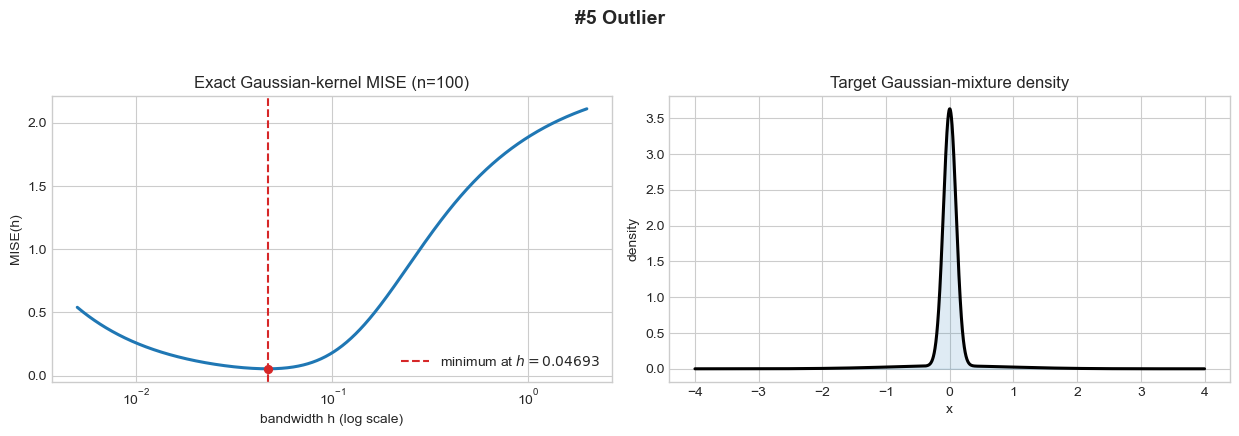

#5 Outlier: 2 component(s), exact MISE minimum h=0.0469343


In [6]:
# 5. Outlier
weights = np.array([1.0 / 10.0, 9.0 / 10.0])
means = np.array([0.0, 0.0])
sigmas = np.array([1.0, 1.0 / 10.0])

MODEL_RESULTS[5] = plot_mise_and_density(
    5, "Outlier", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/006_6_bimodal.pdf


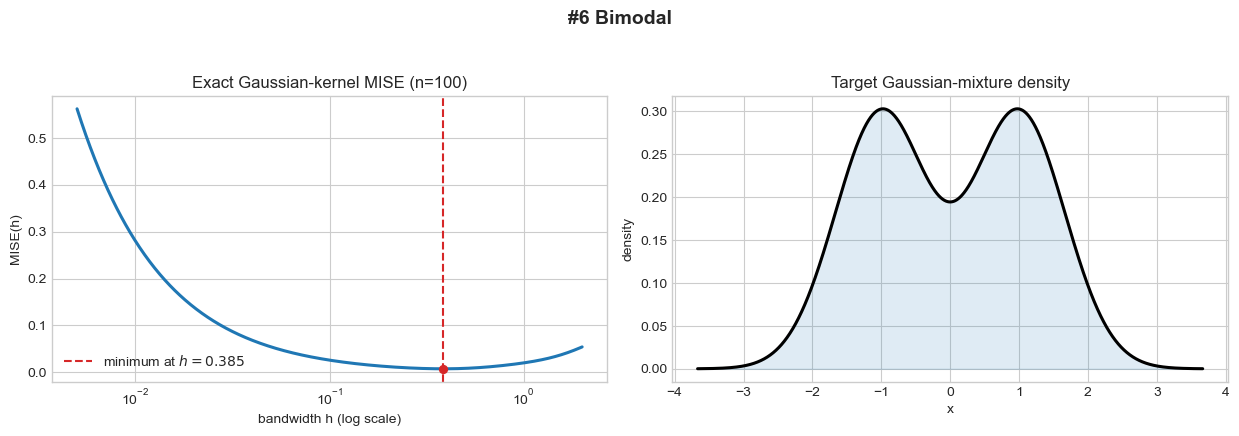

#6 Bimodal: 2 component(s), exact MISE minimum h=0.385002


In [7]:
# 6. Bimodal
weights = np.array([1.0 / 2.0, 1.0 / 2.0])
means = np.array([-1.0, 1.0])
sigmas = np.array([2.0 / 3.0, 2.0 / 3.0])

MODEL_RESULTS[6] = plot_mise_and_density(
    6, "Bimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/007_7_separated_bimodal.pdf


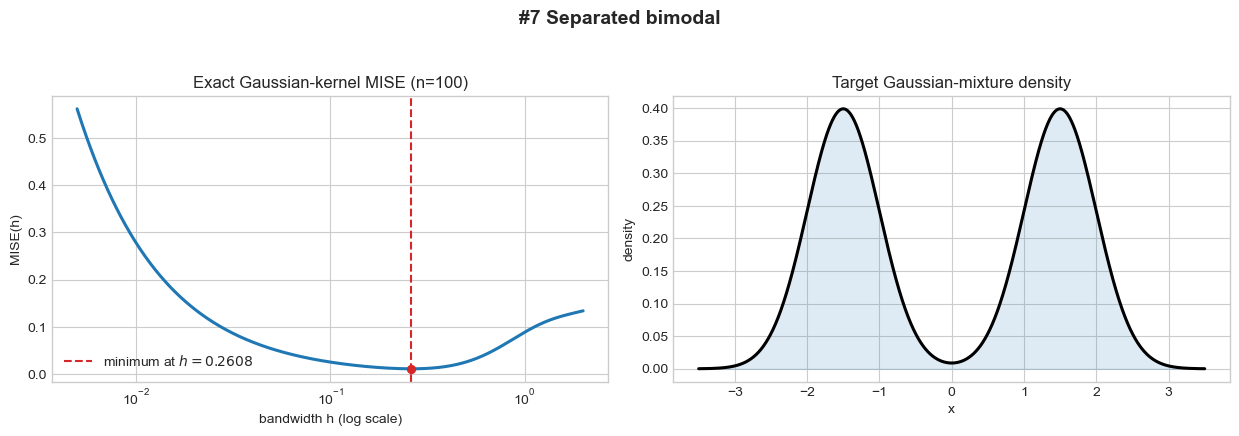

#7 Separated bimodal: 2 component(s), exact MISE minimum h=0.260813


In [8]:
# 7. Separated bimodal
weights = np.array([1.0 / 2.0, 1.0 / 2.0])
means = np.array([-3.0 / 2.0, 3.0 / 2.0])
sigmas = np.array([1.0 / 2.0, 1.0 / 2.0])

MODEL_RESULTS[7] = plot_mise_and_density(
    7, "Separated bimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/008_8_skewed_bimodal.pdf


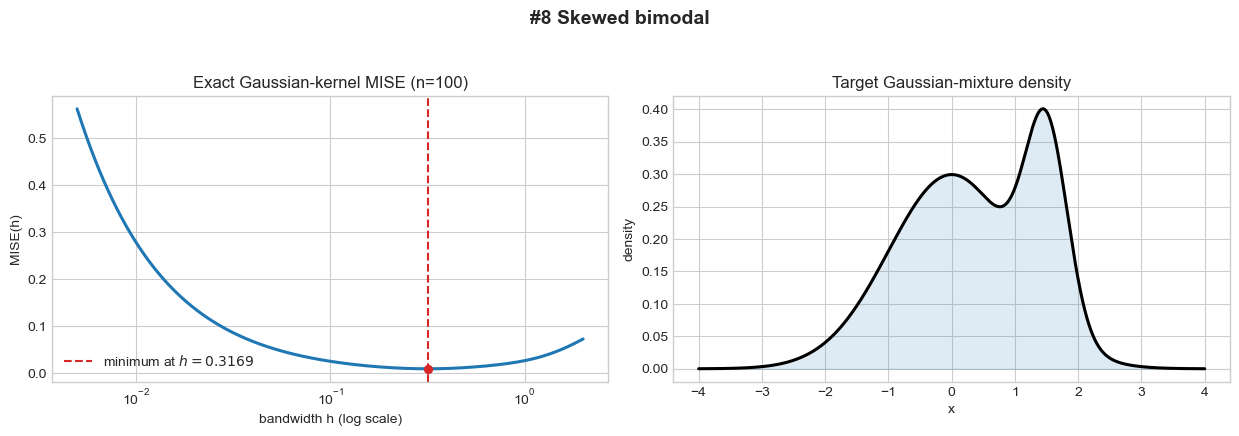

#8 Skewed bimodal: 2 component(s), exact MISE minimum h=0.316881


In [9]:
# 8. Skewed bimodal
weights = np.array([3.0 / 4.0, 1.0 / 4.0])
means = np.array([0.0, 3.0 / 2.0])
sigmas = np.array([1.0, 1.0 / 3.0])

MODEL_RESULTS[8] = plot_mise_and_density(
    8, "Skewed bimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/009_9_trimodal.pdf


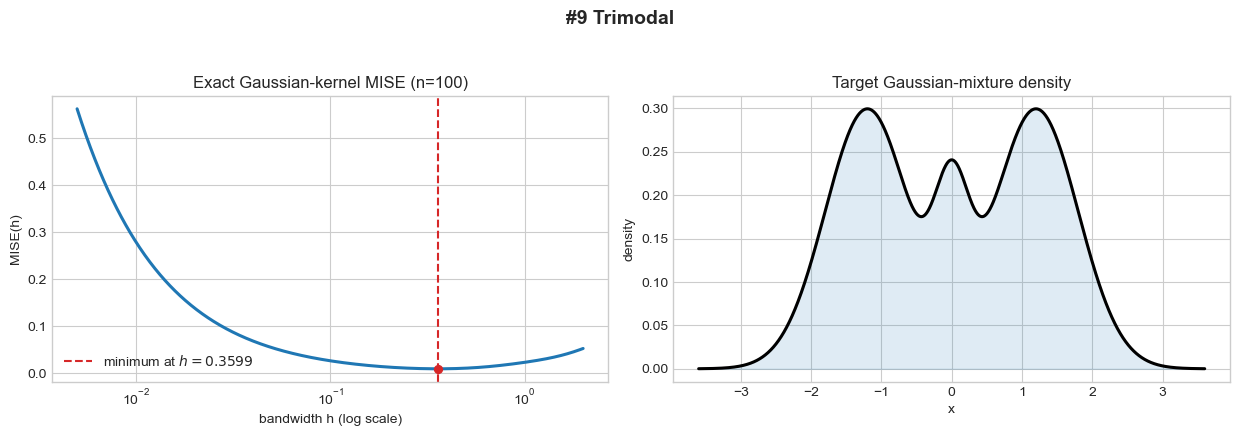

#9 Trimodal: 3 component(s), exact MISE minimum h=0.359907


In [10]:
# 9. Trimodal
weights = np.array([9.0 / 20.0, 9.0 / 20.0, 1.0 / 10.0])
means = np.array([-6.0 / 5.0, 6.0 / 5.0, 0.0])
sigmas = np.array([3.0 / 5.0, 3.0 / 5.0, 1.0 / 4.0])

MODEL_RESULTS[9] = plot_mise_and_density(
    9, "Trimodal", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/010_10_claw.pdf


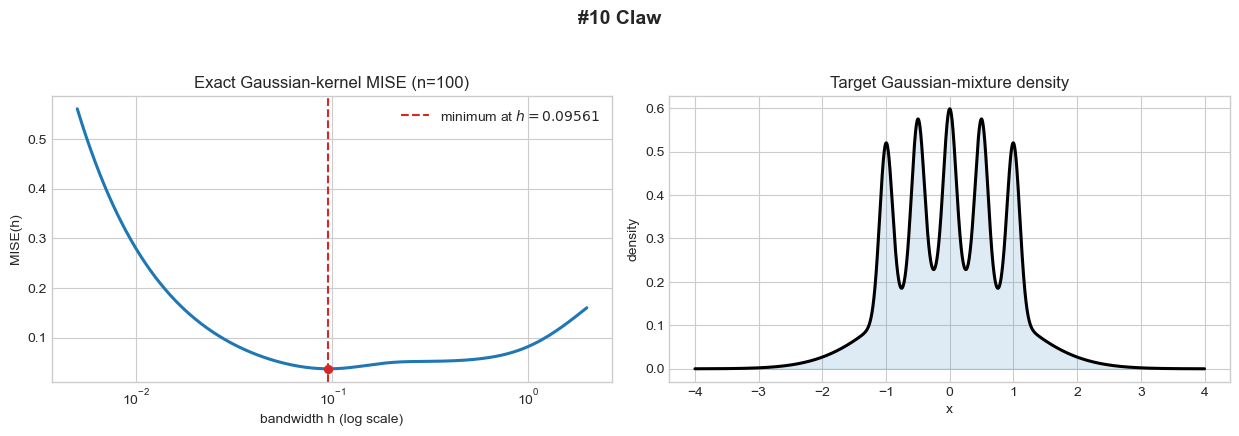

#10 Claw: 6 component(s), exact MISE minimum h=0.0956059


In [11]:
# 10. Claw
claw_index = np.arange(5)
weights = np.r_[1.0 / 2.0, np.full(5, 1.0 / 10.0)]
means = np.r_[0.0, claw_index / 2.0 - 1.0]
sigmas = np.r_[1.0, np.full(5, 1.0 / 10.0)]

MODEL_RESULTS[10] = plot_mise_and_density(
    10, "Claw", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/011_11_double_claw.pdf


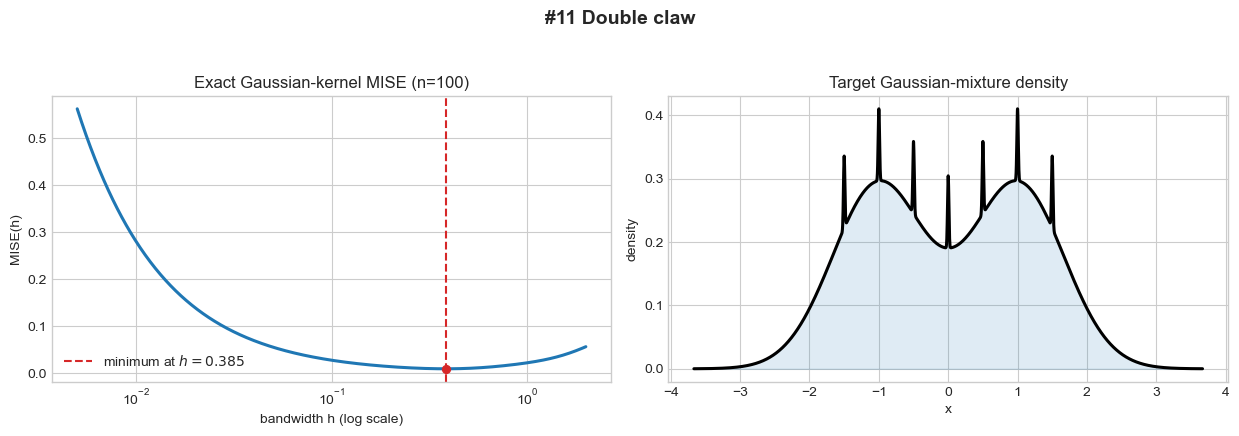

#11 Double claw: 9 component(s), exact MISE minimum h=0.385002


In [12]:
# 11. Double claw
claw_index = np.arange(7)
weights = np.r_[49.0 / 100.0, 49.0 / 100.0, np.full(7, 1.0 / 350.0)]
means = np.r_[-1.0, 1.0, (claw_index - 3.0) / 2.0]
sigmas = np.r_[2.0 / 3.0, 2.0 / 3.0, np.full(7, 1.0 / 100.0)]

MODEL_RESULTS[11] = plot_mise_and_density(
    11, "Double claw", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/012_12_asymmetric_claw.pdf


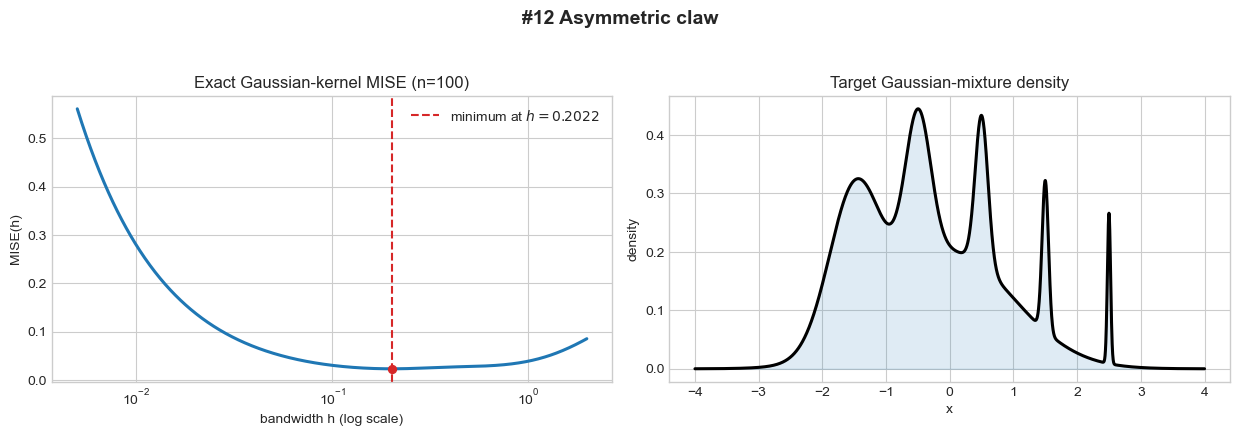

#12 Asymmetric claw: 6 component(s), exact MISE minimum h=0.202182


In [13]:
# 12. Asymmetric claw
claw_index = np.arange(-2, 3)
weights = np.r_[1.0 / 2.0, 2.0 ** (1.0 - claw_index) / 31.0]
means = np.r_[0.0, claw_index + 1.0 / 2.0]
sigmas = np.r_[1.0, 2.0 ** (-claw_index) / 10.0]

MODEL_RESULTS[12] = plot_mise_and_density(
    12, "Asymmetric claw", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/013_13_asymmetric_double_claw.pdf


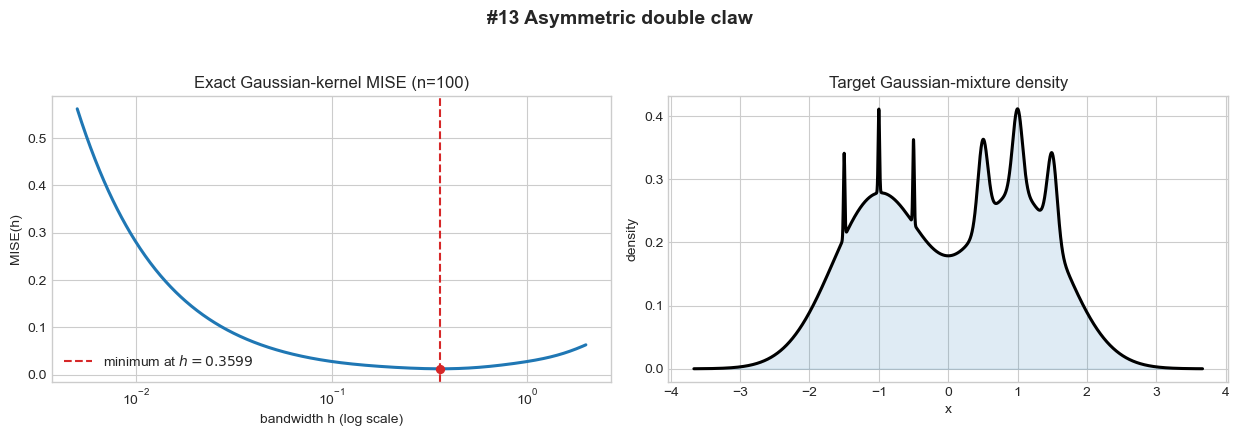

#13 Asymmetric double claw: 8 component(s), exact MISE minimum h=0.359907


In [14]:
# 13. Asymmetric double claw
side_index = np.arange(1, 4)
weights = np.r_[
    46.0 / 100.0,
    46.0 / 100.0,
    np.full(3, 1.0 / 300.0),
    np.full(3, 7.0 / 300.0),
]
means = np.r_[-1.0, 1.0, -side_index / 2.0, side_index / 2.0]
sigmas = np.r_[
    2.0 / 3.0,
    2.0 / 3.0,
    np.full(3, 1.0 / 100.0),
    np.full(3, 7.0 / 100.0),
]

MODEL_RESULTS[13] = plot_mise_and_density(
    13, "Asymmetric double claw", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/014_14_smooth_comb.pdf


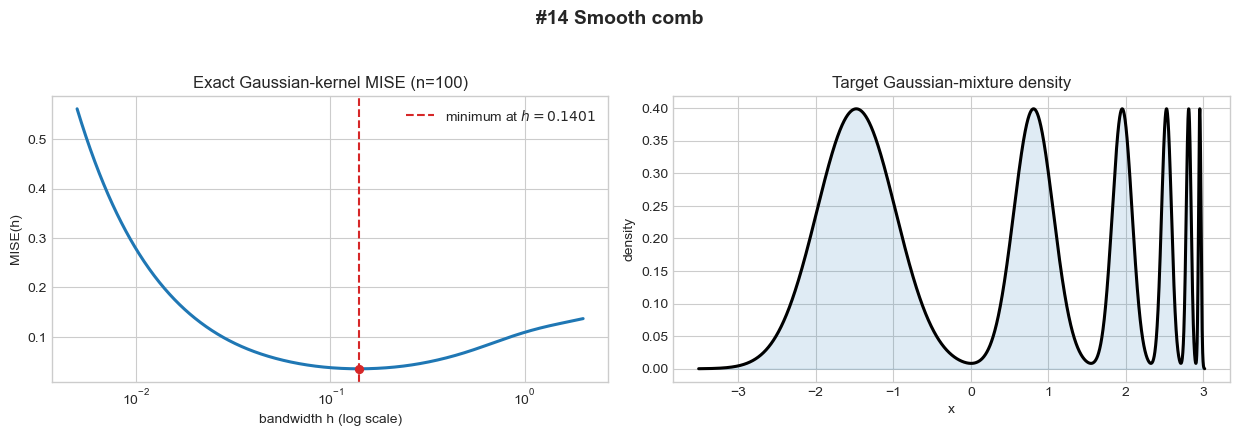

#14 Smooth comb: 6 component(s), exact MISE minimum h=0.140077


In [15]:
# 14. Smooth comb
comb_index = np.arange(6)
weights = 2.0 ** (5.0 - comb_index) / 63.0
means = (65.0 - 96.0 * 2.0 ** (-comb_index)) / 21.0
sigmas = (32.0 / 63.0) / 2.0**comb_index

MODEL_RESULTS[14] = plot_mise_and_density(
    14, "Smooth comb", weights, means, sigmas
)


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/marron_wand_15_gmm_mise_density/015_15_discrete_comb.pdf


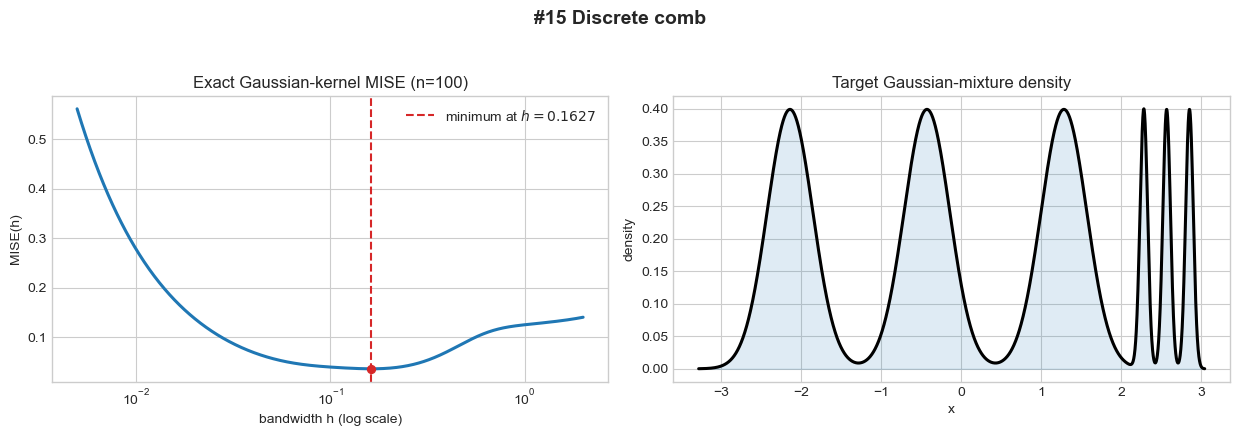

#15 Discrete comb: 6 component(s), exact MISE minimum h=0.162711


In [16]:
# 15. Discrete comb
broad_index = np.arange(3)
narrow_index = np.arange(8, 11)
weights = np.r_[np.full(3, 2.0 / 7.0), np.full(3, 1.0 / 21.0)]
means = np.r_[(12.0 * broad_index - 15.0) / 7.0, 2.0 * narrow_index / 7.0]
sigmas = np.r_[np.full(3, 2.0 / 7.0), np.full(3, 1.0 / 21.0)]

MODEL_RESULTS[15] = plot_mise_and_density(
    15, "Discrete comb", weights, means, sigmas
)
